# Real fluorescence imaging through a scattering layer: I-CLASS


<!-- inverse-evidence-audit:20261026:start -->

> **本次维护说明：** 以下导航依据当前观测文件、实际求解代码和保留的输出编写。本次仅完善叙述，不把历史图、缓存结果或未执行代码称作本次新计算；没有独立 GT 时，方法参考不代表真实准确性。

### 从观测到恢复目标：证据卡

观测文件为 `data/raw_data.npz`（已读取实际NPZ header）：`camera_frames`，shape `(1, 150, 400, 400)`，dtype `<f4`：Fourier-resampled measured intensities in source FFT-resampled camera digital numbers (DN); axes batch, illumination realization, camera row, camera column; no target or transfer calibration is included。未知量为400×400散射后有效荧光物体，峰归一化。

获取模型：随机照明S逐点乘物体O，经未知PSF卷积成为150帧强度。

如何恢复：src.solvers.solve/public_map；I-CLASS相位方向迭代、MTF估计和RMS物体恢复。

GT与评价：没有独立GT；隐藏数组是指定方法输出，比较只说明方法一致性。

已有实验和图：cell3完整帧；6主动run/Judge；8三图物体、相位/MTF及校正前后和独立run0比较。

执行限制：已找到本地恢复路径（可能经review/run_experiments包装）；存档执行输出不等于本次重新运行。本页保留2个含PNG输出的代码cell；本次静态核查没有重跑、补图或新增实验。另次run0曝光不是真值；隐藏参考采用纠正的标准方法图，主函数docstring三key与实际单图契约需区别。

<!-- inverse-evidence-audit:20261026:end -->


## 1. Problem

Reconstruct a fluorescent bead distribution hidden by a scattering layer from 150 experimentally recorded, independently illuminated intensity frames. The unknown detection transfer function must be inferred together with the image. This review reproduces the released phase kernel and explicitly corrects its output formation against supplementary equation S18; it is not a claim of unchanged source reproduction or exact reproduction of the published figure.

Weinberg, Sunray and Katz, Science Advances 10, eadl5218 (2024), DOI: 10.1126/sciadv.adl5218. Source commit `df2d69a0630905c4d6df12bb643e5354f26120e7`. All 150 frames and the full camera field are retained through Fourier resampling, not a central spatial subfield.


## Current benchmark evaluation (v2, 2026-10-29)

The v2 Judge retains independently evaluated image/MTF consistency and the already frozen covariance coherence threshold6.906686629445275, replacing reference-image similarity. No ground truth exists. A distinct smooth-phase candidate with its freshly computed consistent image passes; a random-phase self-consistent image fails covariance quality.31 unit tests passed. Phase-update250 iterations no longer define acceptance. See iclass_pytest.log.

Reference/source-stage and map-similarity comparisons below are retained as historical v1 diagnostics; they do not assert current v2 acceptance boundaries. Current standalone Judge callers retain the same generic report interface.

In [1]:
from pathlib import Path
import sys, time, json
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
assert (ROOT/'data/raw_data.npz').exists(), ROOT
sys.path.insert(0,str(ROOT))
print('Actual kernel:',sys.executable)
from src.preprocessing import load_observations
from src.main import run
from src.visualization import comparison_metrics, review_figure, transfer_figure
import importlib.util
spec=importlib.util.spec_from_file_location('review_judge',ROOT/'evaluation/judge.py')
judge=importlib.util.module_from_spec(spec);spec.loader.exec_module(judge)

Actual kernel: D:\yan1\agent\AutoSkill\imaging-101-maintainer\research-runtime\Scripts\python.exe


## 2. Data

Real acquisition: public Figure 3(D-F) experiment, measurement Run1 (150 frames) and independent no-diffuser Run0 (100 frames). Source collection: https://drive.google.com/drive/folders/1OzmGtAwXmoBArWXEEpnbtg44_nUtv2H6 . Original arrays are 1200 by 1200 pixels. We use the source-supported centered Fourier crop to 400 by 400, with the original inverse-transform gain (9 relative to amplitude-preserving interpolation). No new simulated observations are generated. The nominal detection wavelength is 520 nm; the paper describes a 525/39 nm emission filter. Measurement exposure is 0.2 s and independent widefield exposure 0.005 s. Pixel pitch is unavailable, so plots use camera-grid coordinates.

Run0 is a different measurement, not ground truth: exposure, speckle illumination envelope and windowing differ. It is hidden from the solver and used only for descriptive scientific review.


Bound observations: (150, 400, 400) float32 range 1688.822509765625 87148.765625
Legacy keys: ['reconstruction', 'phase_only', 'phase', 'mtf', 'reference'] corrected upstream keys: ['reconstruction', 'phase', 'mtf', 'phase_only', 'widefield']


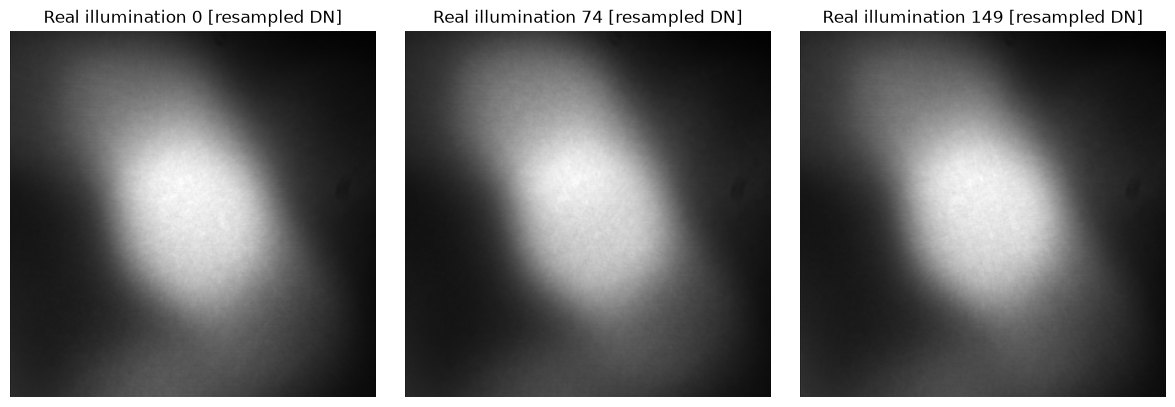

In [2]:
frames=load_observations(ROOT/'data/raw_data.npz')
print('Bound observations:',frames.shape,frames.dtype,'range',float(frames.min()),float(frames.max()))
legacy=np.load(ROOT/'notebooks/reference_outputs/upstream_legacy.npz',allow_pickle=False)
oracle=np.load(ROOT/'notebooks/reference_outputs/upstream_paper_corrected.npz',allow_pickle=False)
print('Legacy keys:',legacy.files,'corrected upstream keys:',oracle.files)
fig,ax=plt.subplots(1,3,figsize=(12,4))
for a,k in zip(ax,[0,74,149]):
 a.imshow(frames[k],cmap='gray');a.set_title(f'Real illumination {k} [resampled DN]');a.axis('off')
plt.tight_layout();plt.show()

## 3. Physics

For frame $m$, $I_m=P*(O S_m)+\epsilon_m$, where $O$ is nonnegative fluorescence, $S_m$ random excitation intensity, $P$ the detection intensity PSF, $*$ spatial convolution and $\epsilon_m$ camera/model error. The isoplanatic, spatially independent illumination approximation gives virtual covariance $V=RR^H$, with $R$ the Fourier-transformed, temporally centered camera matrix. Its phase structure contains the detection aberration. Absolute object brightness and illumination are not independently identifiable.

The code retains the released circular, flattened Fourier-grid convolution convention; this is an explicit discretization departure from the supplement's padded formulation. The test suite verifies it against an independently formed dense covariance. The scalar coherence diagnostic is $J=\sum_d|\sum_a V_{a+d,a}|^2/\mathrm{tr}(V)^2$. It measures covariance alignment, not a fit to a complete camera noise model.

More precisely, the release kernel uses the cyclic flattened index group Z_(H*W), with row ix*H+iy. A shift crossing a y-index boundary carries into x, unlike independent wrapping in Z_H x Z_W. Dense covariance tests validate that released algebra, not exact equivalence to a full 2D optical theorem. Independent physical tests separately use genuine two-dimensional convolution.


## 4. Method

Apply the symmetric 400-pixel Hann window along y then x, subtract each pixel's temporal mean and form $R$ with row $i_x H+i_y$. Each of 250 source-matched phase updates computes a complex covariance direction $z$, projects to $q=\exp(i\arg z)$, and updates $R\leftarrow\mathrm{diag}(q)R$. Cumulative $q$ is the submitted phase correction. The MTF is $h_k=\sqrt{\sum_m|R_{km}|^2/\max_j\sum_m|R_{jm}|^2}$, invariant under these updates.

Corrected output follows S18: divide **each** corrected frame spectrum by $h+\sigma$, with $\sigma=0.01$, restore the two spatial axes, inverse Fourier transform, then compute the RMS over frames and peak-normalize. The released `RtoO` transforms flattened-frequency and illumination axes; its visualization also filters an already-combined RMS image. Both legacy results remain visible below. Independent finite numerical cases verify the physical 2D inverse and per-frame amplitude correction. Sigma is the supplementary balanced setting, not fitted to Run0.

For a self-contained expression of the phase direction, let $N=HW$, $M=150$,
$V=RR^H$ and $s_d=\sum_a V_{(a+d)\bmod N,a}$. The released FFT operations
evaluate $z_n=(N^2M^3)^{-1}\sum_a\overline{V_{n,a}}s_{(n-a)\bmod N}$ without
forming V. Indices n,a,d range from 0 to N-1; the bar is complex conjugation
and H denotes conjugate transpose. Positive scale does not change the phase
projection. Zero direction maps to unit correction. Initialization is all-one
cumulative phase; stopping is exactly 250 updates. No training or data-fitted
stopping rule is used.


In [3]:
started=time.perf_counter()
fresh,details=run(ROOT/'data/raw_data.npz',ROOT/'output/reconstruction.npz')
report=judge.evaluate(ROOT/'output/reconstruction.npz')
(ROOT/'output/judge_report.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print('Fresh runtime:',details['runtime_seconds'],'device:',details['device'])
print('Coherence initial/final:',details['initial_coherence'],details['final_coherence'])
print(json.dumps(report,indent=2))
assert report['passed']
np.savez_compressed(ROOT/'notebooks/reference_outputs/cleaned_measurements.npz',
 reconstruction=fresh['reconstruction'],phase=fresh['phase'],mtf=fresh['mtf'],
 phase_only=details['phase_only'],raw_rms=details['raw_rms'])

Fresh runtime: 15.587855000048876 device: cuda
Coherence initial/final: 6.572206974029541 7.270197868347168
{
  "status": "pass",
  "passed": true,
  "metrics": {
    "ncc_vs_ref": 0.9999999999999961,
    "nrmse_vs_ref": 7.957373654958354e-09,
    "image_consistency": 3.074701668136098e-07,
    "mtf_consistency": 3.655017697047144e-08,
    "covariance_coherence": 7.270196452047658
  },
  "thresholds": {
    "ncc_vs_ref": {
      "comparison": ">=",
      "boundary": 0.999
    },
    "nrmse_vs_ref": {
      "comparison": "<=",
      "boundary": 0.001
    },
    "image_consistency": {
      "comparison": "<=",
      "boundary": 0.0002
    },
    "mtf_consistency": {
      "comparison": "<=",
      "boundary": 2e-05
    },
    "covariance_coherence": {
      "comparison": ">=",
      "boundary": 6.906686629445275
    }
  },
  "errors": []
}


## 5. Results

The saved code and outputs below belong to the existing notebook execution. This documentation review preserves those measurements and does not rerun reconstruction; “fresh” in the retained experiment narrative distinguishes the local run from the separately captured upstream result.

Every fresh image in this section was computed by the preceding active reconstruction. Archived source output and source-phase/paper-corrected output are separately labeled. Display images are individually peak-normalized to [0,1]; no background subtraction, denoising, invented pixels or unreported filter is used. The independent widefield has different acquisition conditions; its NCC/NRMSE describe cross-measurement agreement and do not establish absolute accuracy.


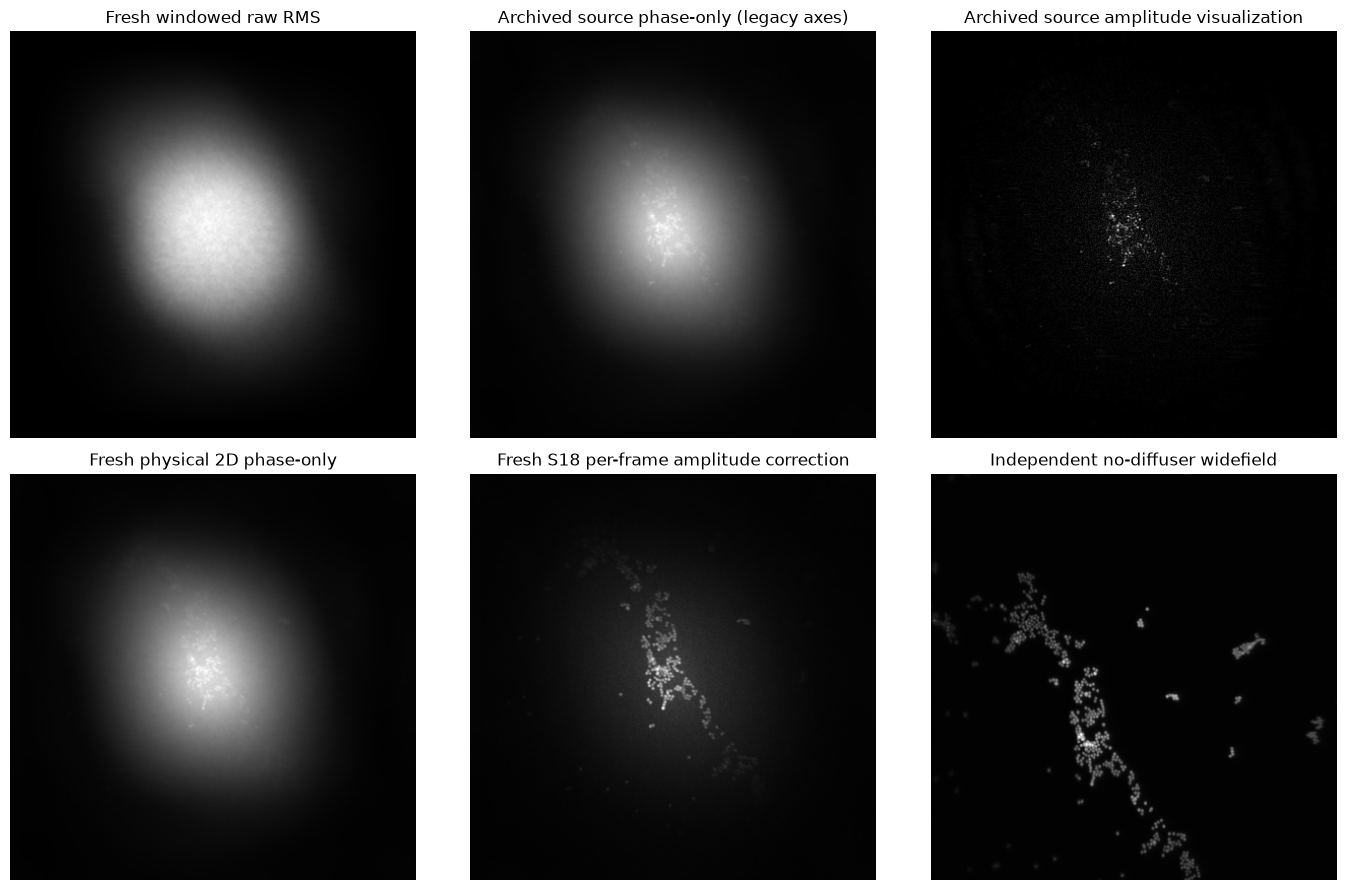

[
  {
    "method": "Fresh windowed raw RMS",
    "ncc": 0.43988508160685863,
    "nrmse": 0.25878060298816186,
    "shift": [
      44,
      -44
    ],
    "contrast": 0.9350109466242825
  },
  {
    "method": "Archived source phase-only (legacy axes)",
    "ncc": 0.4745247408736788,
    "nrmse": 0.19652649429794097,
    "shift": [
      52,
      -39
    ],
    "contrast": 0.9235460850262107
  },
  {
    "method": "Archived source amplitude visualization",
    "ncc": 0.5766170243635433,
    "nrmse": 0.0478339698353343,
    "shift": [
      75,
      -31
    ],
    "contrast": 0.9178464652620245
  },
  {
    "method": "Fresh physical 2D phase-only",
    "ncc": 0.47469396753200893,
    "nrmse": 0.19736007678646988,
    "shift": [
      51,
      -39
    ],
    "contrast": 0.9235618242266395
  },
  {
    "method": "Fresh S18 per-frame amplitude correction",
    "ncc": 0.644440573579962,
    "nrmse": 0.06264631478393401,
    "shift": [
      74,
      -31
    ],
    "contrast": 0.883183

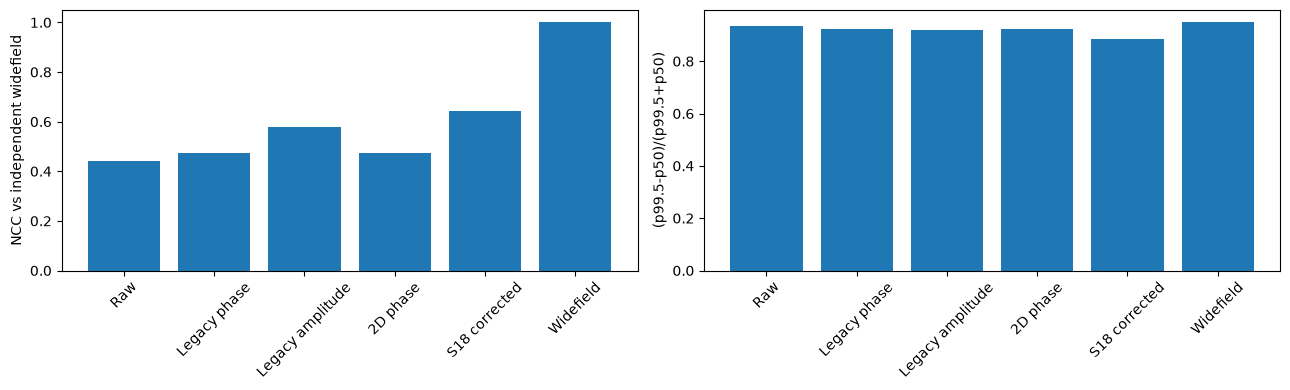

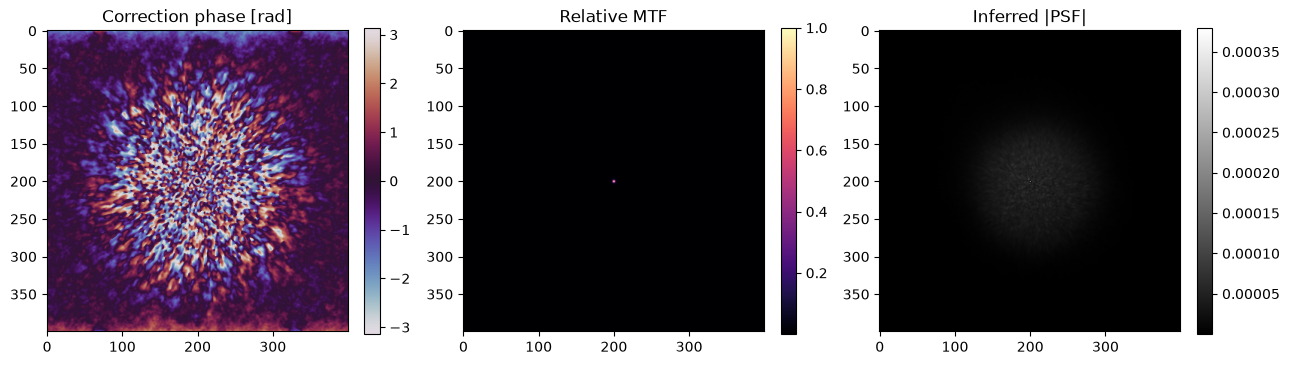

Fresh vs corrected source: {'ncc': 0.9999999999999959, 'nrmse': 7.957373654958354e-09, 'shift': (0, 0), 'contrast': 0.8831839267812823}
Covariance gain ratio: 1.106203425588357


In [4]:
widefield=legacy['reference'][0]
images=[details['raw_rms'][0],legacy['phase_only'][0],legacy['reconstruction'][0],
        details['phase_only'][0],fresh['reconstruction'][0],widefield]
titles=['Fresh windowed raw RMS','Archived source phase-only (legacy axes)',
 'Archived source amplitude visualization','Fresh physical 2D phase-only',
 'Fresh S18 per-frame amplitude correction','Independent no-diffuser widefield']
review_figure(images,titles);plt.show()
rows=[]
for title,im in zip(titles,images):
 row={'method':title,**comparison_metrics(im,widefield)};rows.append(row)
print(json.dumps(rows,indent=2))
fig,ax=plt.subplots(1,2,figsize=(13,4))
labels=['Raw','Legacy phase','Legacy amplitude','2D phase','S18 corrected','Widefield']
ax[0].bar(labels,[r['ncc'] for r in rows]);ax[0].set_ylabel('NCC vs independent widefield')
ax[1].bar(labels,[r['contrast'] for r in rows]);ax[1].set_ylabel('(p99.5-p50)/(p99.5+p50)')
for a in ax:a.tick_params(axis='x',rotation=45)
plt.tight_layout();plt.show()
transfer_figure(fresh['phase'][0],fresh['mtf'][0]);plt.show()
print('Fresh vs corrected source:',comparison_metrics(fresh['reconstruction'][0],oracle['reconstruction'][0]))
print('Covariance gain ratio:',details['final_coherence']/details['initial_coherence'])

## 6. Conclusion

The local phase kernel agrees with frozen upstream stages and the full 250-update result. The corrected physical 2D/S18 output recovers the main bead chain, while substantial haze and weak/edge bead loss remain. Widefield agreement is limited by illumination and envelope differences; it is not a truth-based resolution or quantitative concentration result. The phase and MTF are effective transfer estimates under a circular isoplanatic covariance model, with translation/piston ambiguities.

This bound task retains all experimental illuminations and the full field at a declared lower Fourier sampling. It does not reproduce unknown processing coordinates from the published figure or certify the paper's full megapixel claims. Independent covariance, FFT, per-frame inverse, upstream parity, CPU/GPU and standalone Judge tests are indexed in `test/validation.md`.


The independent no-diffuser exposure is a different illumination measurement, not bead truth. Corrected per-frame S18 output and released legacy outputs remain separate groups. Flattened cyclic covariance is the released discretization; it is not silently equated with a padded two-dimensional optical operator.
